# №11. Границы изображения: алгоритм Кэнни

Найдём контуры окон, арок и стен. Этапы: гауссово сглаживание, градиенты Собеля,
модуль и направление, утончение, пороги и прослеживание слабых границ.
Все алгоритмы реализованы на NumPy. Pillow читает фотографию, Matplotlib строит графики.

Координата $x$ растёт вправо, $y$ — вниз. Яркость имеет диапазон 0–255;
промежуточные массивы используют `float64`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    if figsize is None:
        figsize = (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 1. Фотография и параметры

Переводим RGB в серое по весам BT.601. Пороги задаются в единицах модуля градиента:
ядра Собеля ниже нормированы делением на 8. Размер гауссова окна задаётся явно.

shape: (480, 720) dtype: float64


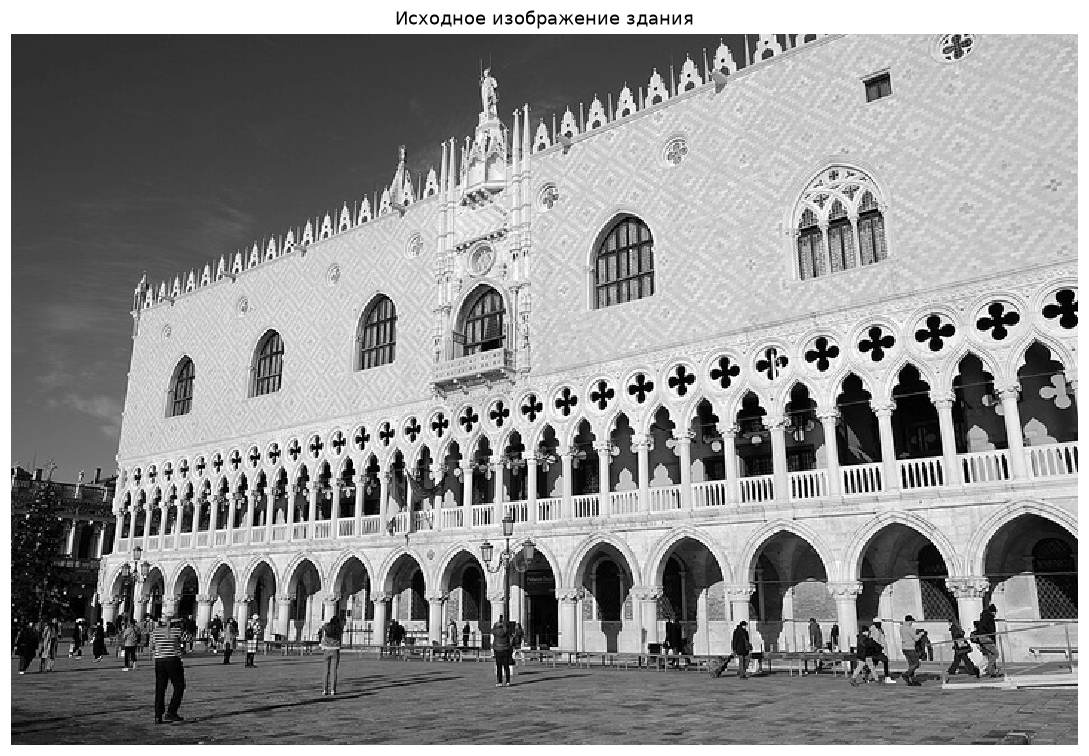

In [3]:
rgb = np.array(Image.open('data/building.jpg').convert('RGB')).astype(float)
image = rgb @ np.array([0.299, 0.587, 0.114])

SIGMA = 1.2
WINDOW = 9
LOW_THRESHOLD = 6.0
HIGH_THRESHOLD = 15.0

print('shape:', image.shape, 'dtype:', image.dtype)
show_images([image], ['Исходное изображение здания'], cols=1, figsize=(10, 7))

## 2. Сглаживание и градиенты

Используем корреляцию: ядро умножается на окно в записанном порядке.
$C(y,x)=\sum_{i,j}K(i,j)I(y+i-r_y,x+j-r_x)$.
Для симметричного гауссова ядра эта операция совпадает со свёрткой.
Поля за краем дополняются отражением.

Ядро $K_x$ имеет слева коэффициенты $-1,-2,-1$, справа $1,2,1$.
Поэтому рост яркости вправо даёт положительный $g_x$. Транспонированное ядро
$K_y$ даёт положительный $g_y$ при росте яркости вниз.

In [4]:
def correlate2d(image, kernel):
    """Корреляция серого изображения с ядром; края дополняются отражением."""
    image = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    kh, kw = kernel.shape
    height, width = image.shape
    padded = np.pad(image, ((kh // 2, kh // 2), (kw // 2, kw // 2)), mode='reflect')
    result = np.zeros_like(image)
    for iy in range(kh):
        for ix in range(kw):
            result += kernel[iy, ix] * padded[iy:iy + height, ix:ix + width]
    return result


def gaussian_kernel(size, sigma):
    coords = np.arange(size) - size // 2
    x, y = np.meshgrid(coords, coords)
    kernel = np.exp(-(x * x + y * y) / (2 * sigma * sigma))
    return kernel / kernel.sum()


def sobel_gradients(image):
    kernel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float) / 8
    gx = correlate2d(image, kernel_x)
    gy = correlate2d(image, kernel_x.T)
    return gx, gy


def gradient_direction(gx, gy):
    """Угол 0…360° и ближайший из восьми секторов; код −1 означает нулевой модуль."""
    magnitude = np.hypot(gx, gy)
    angle = np.degrees(np.arctan2(gy, gx)) % 360
    directions = (np.floor((angle + 22.5) / 45).astype(int) % 8)
    valid = magnitude > 1e-10
    return np.where(valid, angle, np.nan), np.where(valid, directions, -1)

## 3. Подавление локальных немаксимумов

Модуль $M=\sqrt{g_x^2+g_y^2}$ измеряет силу перепада. Направление градиента
перпендикулярно контуру. Округляем угол до ближайшего кратного 45°.
В системе с $y$ вниз положительный угол идёт по часовой стрелке.

Для каждого пикселя сравниваем $M$ с двумя соседями вдоль градиента.
Противоположные направления задают одну ось. Оставляем пиксель при
$M\geq M_+$ и $M>M_-$. Строгое сравнение с одной стороны выбирает один пиксель
на короткой площадке равных максимумов. Внешняя строка и внешний столбец с каждой
стороны получают ноль: для них пара соседей выходит за кадр.

In [5]:
def non_maximum_suppression(magnitude, directions):
    """Утончение вдоль четырёх осей, заданных восемью направлениями."""
    magnitude = np.asarray(magnitude, dtype=float)
    height, width = magnitude.shape
    result = np.zeros_like(magnitude)
    center = magnitude[1:-1, 1:-1]
    codes = directions[1:-1, 1:-1]
    # Порядок: вправо, вниз-вправо, вниз, вниз-влево; пары записаны как (dy, dx).
    offsets = [(0, 1), (1, 1), (1, 0), (1, -1)]
    for axis, (dy, dx) in enumerate(offsets):
        ahead = magnitude[1 + dy:height - 1 + dy, 1 + dx:width - 1 + dx]
        behind = magnitude[1 - dy:height - 1 - dy, 1 - dx:width - 1 - dx]
        keep = ((codes >= 0) & (codes % 4 == axis) & (center > 0)
                & (center >= ahead) & (center > behind))
        result[1:-1, 1:-1][keep] = center[keep]
    return result

## 4. Пороги и прослеживание границ

Один высокий порог выделяет сильные фрагменты. Два порога задают три класса:
фон ($M<T_l$), слабая граница ($T_l\leq M<T_h$) и сильная граница ($M\geq T_h$).

Начинаем обход со всех сильных пикселей и присоединяем соседние слабые.
Используем восемь соседей, включая диагональные. Каждый присоединённый пиксель
продолжает обход, поэтому сохраняется вся связанная цепочка. Обход заканчивается,
когда стек опустеет. В итог входят компоненты кандидатов, содержащие сильный пиксель.

In [6]:
def hysteresis(magnitude, low, high):
    """Два порога и обход слабых границ, связанных с сильными."""
    height, width = magnitude.shape
    labels = np.zeros(magnitude.shape, dtype=np.uint8)
    labels[magnitude >= low] = 1
    labels[magnitude >= high] = 2
    edges = labels == 2
    stack = list(zip(*np.nonzero(edges)))
    neighbours = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                  if (dy, dx) != (0, 0)]
    while stack:
        y, x = stack.pop()
        for dy, dx in neighbours:
            yy, xx = y + dy, x + dx
            if 0 <= yy < height and 0 <= xx < width:
                if labels[yy, xx] > 0 and not edges[yy, xx]:
                    edges[yy, xx] = True
                    stack.append((yy, xx))
    return edges, labels


def canny(image, sigma=1.2, window=9, low=6, high=15):
    smooth = correlate2d(image, gaussian_kernel(window, sigma))
    gx, gy = sobel_gradients(smooth)
    magnitude = np.hypot(gx, gy)
    angle, directions = gradient_direction(gx, gy)
    thin = non_maximum_suppression(magnitude, directions)
    edges, labels = hysteresis(thin, low, high)
    return {'smooth': smooth, 'gx': gx, 'gy': gy, 'magnitude': magnitude,
            'angle': angle, 'directions': directions, 'thin': thin,
            'labels': labels, 'edges': edges}

## 5. Результаты на здании

Знак градиента показан симметричной цветовой шкалой: синий — отрицательные значения,
красный — положительные. Оба компонента используют одинаковый предел шкалы.

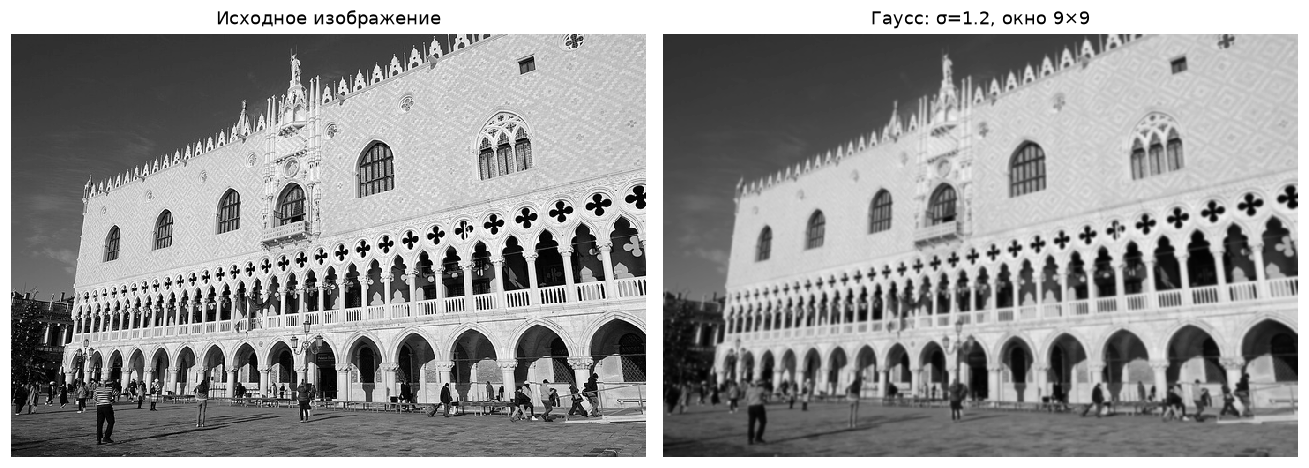

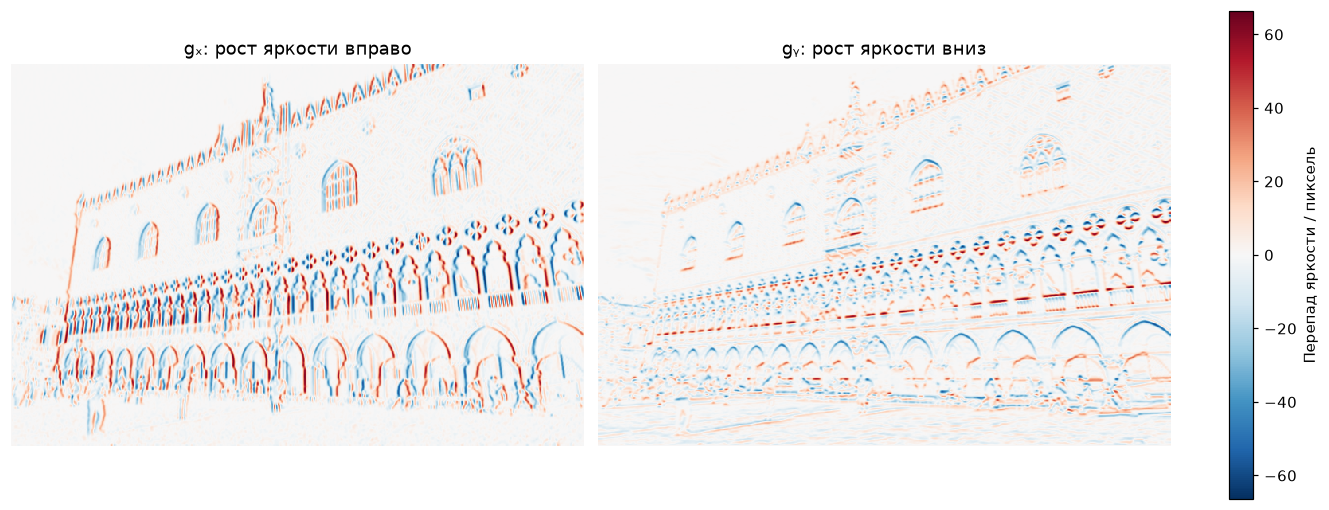

In [7]:
result = canny(image, SIGMA, WINDOW, LOW_THRESHOLD, HIGH_THRESHOLD)
show_images([image, result['smooth']], ['Исходное изображение', f'Гаусс: σ={SIGMA}, окно {WINDOW}×{WINDOW}'],
            cols=2, figsize=(12, 7))

limit = max(np.abs(result['gx']).max(), np.abs(result['gy']).max())
fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, key, title in zip(axes, ['gx', 'gy'], ['gₓ: рост яркости вправо', 'gᵧ: рост яркости вниз']):
    plot = ax.imshow(result[key], cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_title(title)
    ax.axis('off')
fig.colorbar(plot, ax=axes, shrink=0.75, label='Перепад яркости / пиксель')
plt.show()

## 6. Модуль и восемь направлений

Цвет задаёт сектор градиента: 0° направлен вправо, 90° — вниз, 180° — влево,
270° — вверх. При нулевом модуле направление скрыто чёрным. Угол на границе
секторов относится к следующему сектору по часовой стрелке.

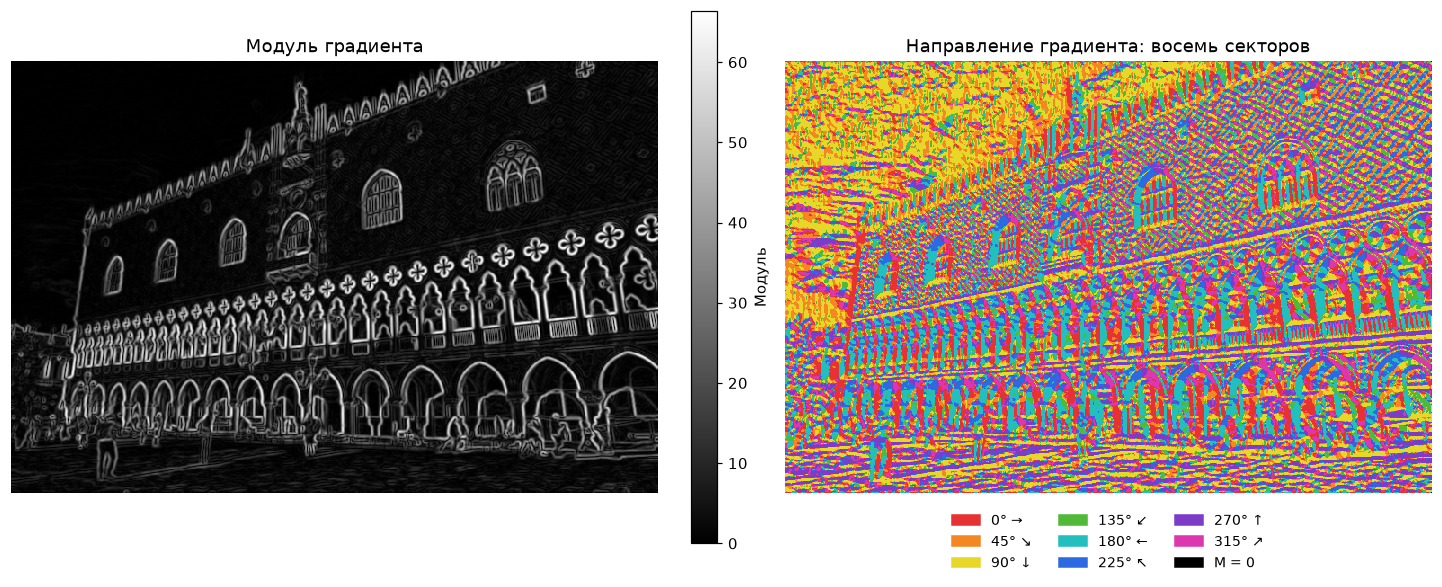

In [8]:
palette = np.array([[230, 50, 50], [245, 135, 35], [230, 215, 40], [80, 185, 55],
                    [35, 190, 190], [45, 105, 225], [125, 60, 200], [220, 55, 175]], dtype=np.uint8)
direction_rgb = np.zeros((*image.shape, 3), dtype=np.uint8)
valid = result['directions'] >= 0
direction_rgb[valid] = palette[result['directions'][valid]]

fig, axes = plt.subplots(1, 2, figsize=(13, 7), constrained_layout=True)
maximum = result['magnitude'].max()
plot = axes[0].imshow(result['magnitude'], cmap='gray', vmin=0, vmax=maximum)
axes[0].set_title('Модуль градиента')
axes[1].imshow(direction_rgb)
axes[1].set_title('Направление градиента: восемь секторов')
for ax in axes:
    ax.axis('off')
fig.colorbar(plot, ax=axes[0], shrink=0.7, label='Модуль')
labels = ['0° →', '45° ↘', '90° ↓', '135° ↙', '180° ←', '225° ↖', '270° ↑', '315° ↗']
handles = [Patch(color=color / 255, label=label) for color, label in zip(palette, labels)]
handles.append(Patch(color='black', label='M = 0'))
axes[1].legend(handles=handles, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.02),
               frameon=False, fontsize=9)
plt.show()

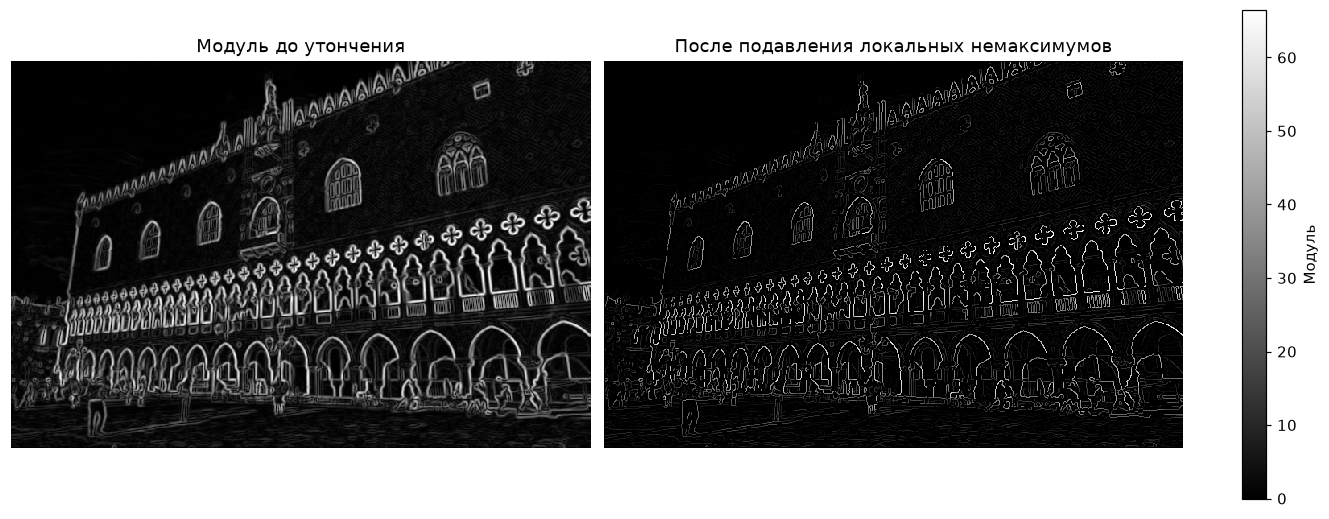

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
for ax, values, title in zip(axes, [result['magnitude'], result['thin']],
                             ['Модуль до утончения', 'После подавления локальных немаксимумов']):
    plot = ax.imshow(values, cmap='gray', vmin=0, vmax=maximum)
    ax.set_title(title)
    ax.axis('off')
fig.colorbar(plot, ax=axes, shrink=0.75, label='Модуль')
plt.show()

## 7. Один порог и двойная пороговая фильтрация

Сильные пиксели служат началом линий. Прослеживание присоединяет слабые участки
окон и арок, которые связаны с сильными по восьми соседям. Цветная разметка
показывает кандидатов до обхода.

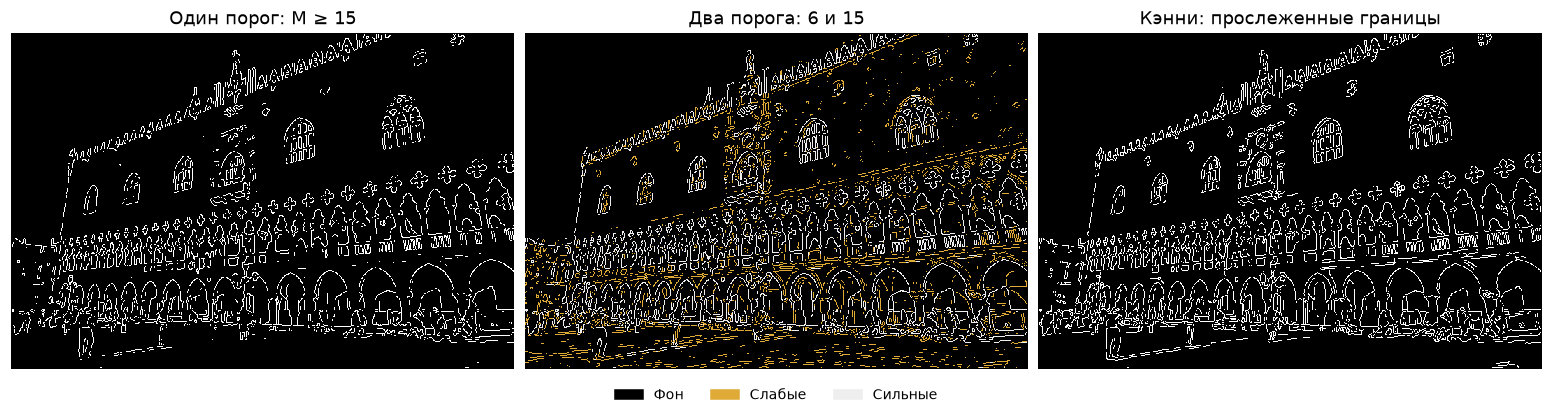

Сильных пикселей: 22319
Слабых кандидатов: 16618
Присоединённых слабых: 5733
Пикселей итогового контура: 28052


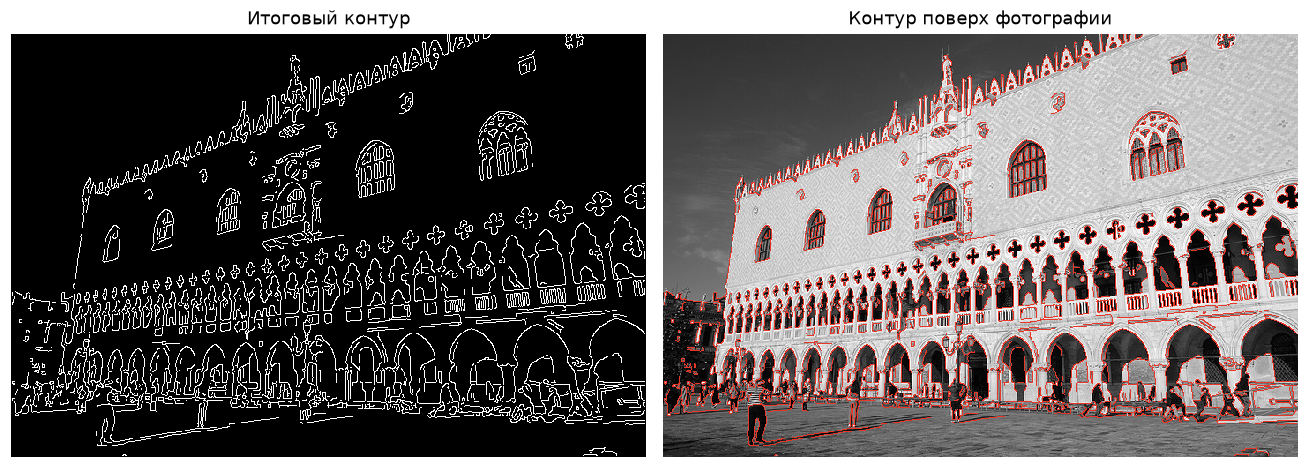

In [10]:
single = result['thin'] >= HIGH_THRESHOLD
fig, axes = plt.subplots(1, 3, figsize=(14, 6), constrained_layout=True)
axes[0].imshow(single, cmap='gray', vmin=0, vmax=1)
axes[0].set_title(f'Один порог: M ≥ {HIGH_THRESHOLD:g}')
axes[1].imshow(result['labels'], cmap=ListedColormap(['black', '#dfaa35', '#eeeeee']), vmin=0, vmax=2)
axes[1].set_title(f'Два порога: {LOW_THRESHOLD:g} и {HIGH_THRESHOLD:g}')
axes[1].legend(handles=[Patch(color='black', label='Фон'), Patch(color='#dfaa35', label='Слабые'),
                       Patch(color='#eeeeee', label='Сильные')], ncol=3,
               loc='upper center', bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=9)
axes[2].imshow(result['edges'], cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Кэнни: прослеженные границы')
for ax in axes:
    ax.axis('off')
plt.show()

print('Сильных пикселей:', np.count_nonzero(single))
print('Слабых кандидатов:', np.count_nonzero(result['labels'] == 1))
print('Присоединённых слабых:', np.count_nonzero(result['edges'] & (result['labels'] == 1)))
print('Пикселей итогового контура:', np.count_nonzero(result['edges']))


overlay = np.repeat(np.clip(np.rint(image), 0, 255).astype(np.uint8)[..., None], 3, axis=2)
overlay[result['edges']] = [230, 55, 40]
show_images([result['edges'].astype(np.uint8) * 255, overlay],
            ['Итоговый контур', 'Контур поверх фотографии'], cols=2, figsize=(12, 7))

## 8. Влияние параметров

Верхний ряд меняет сглаживание при фиксированных порогах. Нижний ряд меняет
пороги при фиксированном сглаживании. Центральные изображения служат общей
точкой сравнения. При увеличении $\sigma$ мелкие детали сглаживаются;
низкие пороги сохраняют больше слабых линий и фактуры.

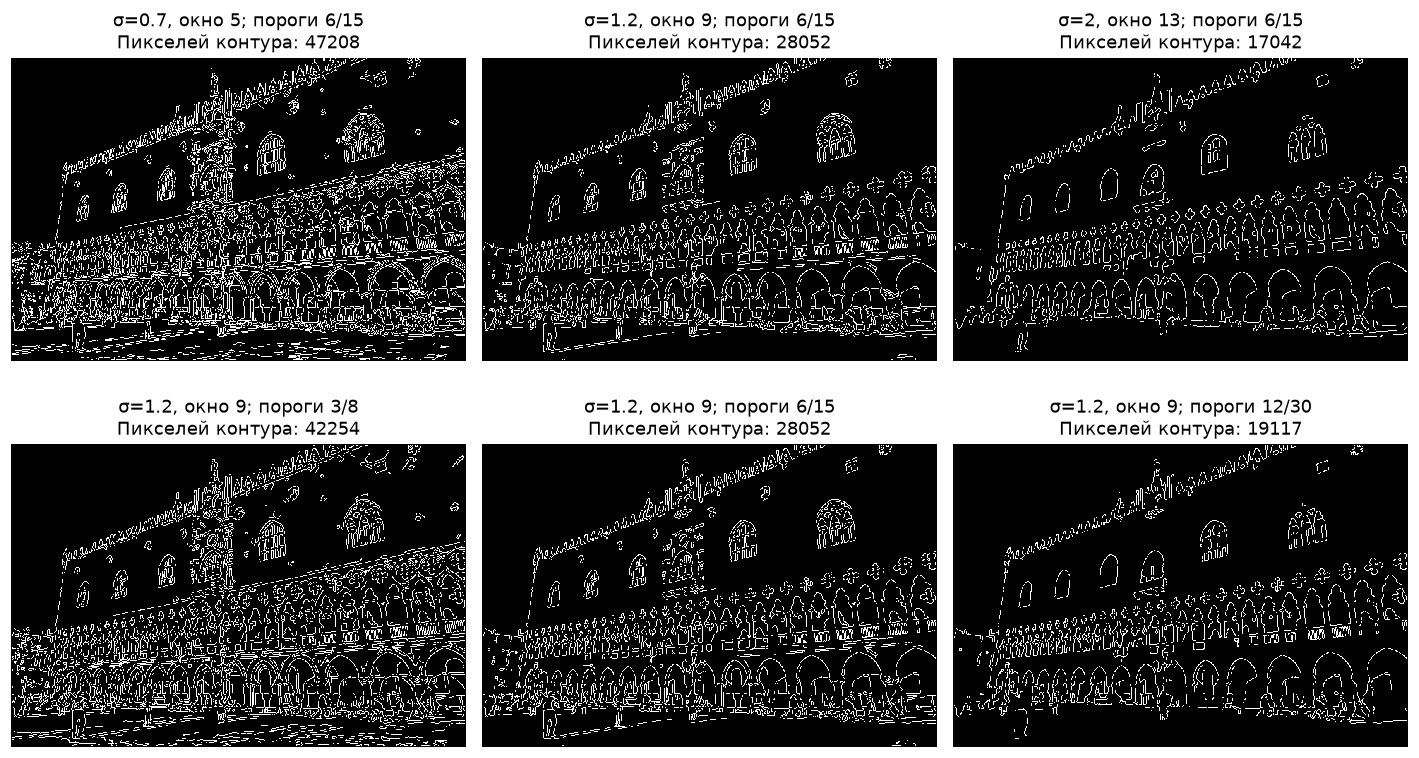

In [11]:
settings = [(0.7, 5, 6, 15), (1.2, 9, 6, 15), (2.0, 13, 6, 15),
            (1.2, 9, 3, 8), (1.2, 9, 6, 15), (1.2, 9, 12, 30)]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, (sigma, window, low, high) in zip(axes.flat, settings):
    variation = canny(image, sigma=sigma, window=window, low=low, high=high)
    count = np.count_nonzero(variation['edges'])
    ax.imshow(variation['edges'], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'σ={sigma:g}, окно {window}; пороги {low}/{high}\nПикселей контура: {count}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Вывод

Градиенты выделяют перепады яркости стен, окон и арок. Восемь цветов показывают
их ориентацию. Подавление локальных немаксимумов сужает полосы отклика до линий.
Двойной порог и обход сохраняют слабые продолжения сильных контуров. Настройка
сглаживания и порогов определяет количество деталей в итоговой маске.

Источник алгоритма: лекция курса
[«Границы на изображении»](../11.%20Границы%20на%20изображении.pdf),
слайд «Алгоритм Кэнни». Источник фотографии указан в [описании данных](../data/SOURCES.md).